# Programming Assignment: Rosenbrock Minimization

**Core: 100 points. Optional BB bonus: +25 points.**

Complete the TODO code and the **Solution** fields. Use NumPy, SciPy linear algebra,
and Matplotlib; do not use optimization solvers or automatic differentiation.
Complete the relevant functions before running a check or experiment.

Submit a single completed .ipynb file containing your code, written answers, and all required
outputs, including tables and figures. Write your answers in the corresponding Markdown cells.
No PDF or additional files are required.

## Rosenbrock problem

Minimize
$$
f(\mathbf{x})=\sum_{i=1}^{n-1}\left[100(x_{i+1}-x_i^2)^2+(1-x_i)^2\right].
$$
For the main experiments, use $n=1000$,
$\mathbf{x}_0=(-1.2,1,-1.2,1,\ldots)^\top$, and float64.
The global minimum is $f^*=0$ at $\mathbf{x}^*=\mathbf{1}$.
A small gradient alone does not establish global optimality.

| Part | Topic | Points |
|:--|:--|--:|
| 1 | Derivatives and Numerical Verification | 20 |
| 2 | Optimization Algorithms | 40 |
| 3 | Numerical Experiments and Discussion | 40 |
| Bonus | Barzilai–Borwein methods | +25 |

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter
import scipy.linalg


def initial_point(n):
    """Input: dimension n (integer >= 2). Return: float64 vector of length n."""
    x = np.ones(n, dtype=np.float64)
    x[::2] = -1.2
    return x


def objective(x):
    """Input: float vector x of length n. Return: scalar Rosenbrock value."""
    return np.sum(100 * (x[1:] - x[:-1]**2)**2 + (1 - x[:-1])**2)

## Part 1: Derivatives and Numerical Verification (20 points)

### Task 1: Analytical derivatives (8 points)

1. Write the gradient components for general $n\ge2$, including both boundary components.

   **Solution:**
   
   For 2 <= i <= n-1:
   
   $$
   \frac{\mathbf{d} f}{\mathbf{d} x_i} = 400 x_i^3 + (-400 x_{i+1} + 202) x_i - 200 x_{i-1}^2 - 2
   $$

   Boundary components:

   $$
   \frac{\mathbf{d} f}{\mathbf{d} x_1} = 400 x_1^3 - 400 x_1 x_2 + 2 x_1 - 2
   $$

   $$
   \frac{\mathbf{d} f}{\mathbf{d} x_n} = 200 x_n - 200 x_{n-1}^2
   $$

2. Write all nonzero Hessian entries, including the boundary entries.

   **Solution:**
   
   $$
   \text{Hessian Matrix} =

   \begin{pmatrix}
   1200 x_1^2 - 400 x_2 + 2 & -400 x_1 & & & & & & \\
   -400 x_1 & 1200 x_2^2 - 400 x_3 + 202 & -400 x_2 & & & & & \\
    & -400 x_2 & 1200 x_3^2 - 400 x_4 + 202 & \ddots & & & & \\
    & & \ddots & \ddots & -400 x_i & & &  \\
    & & & -400 x_i & 1200 x_i^2 - 400 x_{i+1} + 202 & \ddots & \\
    & & & & \ddots & \ddots & & -400 x_n \\
    & & & & & & -400 x_n & 200
   \end{pmatrix}
   $$

3. Implement **gradient** using vectorized NumPy operations, without a loop over coordinates.

Final formulas are sufficient for Questions 1 and 2.

In [21]:
def gradient(x):
    """Input: float vector x (n,). Return: gradient g, a float vector (n,)."""
    g = np.zeros_like(x)
    t = x[1:] - x[:-1]**2
    g[:-1] += -400 * x[:-1] * t + 2 * (x[:-1] - 1)
    g[1:]  += 200 * t
    return g

### Task 2: Hessian structure (7 points)

1. Why is the Hessian tridiagonal? Relate its nonzero entries to the variables in each summand.

   **Solution:** $x_i$ and $x_j$ will occur in a format of product if and only if $\vert i - j \vert \leq 1$, so it's a tridiagonal matrix.

2. Compare a dense Hessian with the banded storage below. Give the allocated number of
   scalars and the float64 storage in bytes, as functions of $n$.

   **Solution:** When using dense format, it assigns $n \times n$ scalars and $8 \times n \times n$ bytes; When using banded storage, it assigns $3 \times n$ scalars and $24 \times n$ bytes.

3. What computational advantage does the tridiagonal structure offer when solving a linear
   system, compared with a general dense matrix? State the respective orders of cost.

   **Solution:** When solving $\mathbf{A} \mathbf{x} = \mathbf{b}$, Gaussian elimination costs $O(n^3)$ in a dense format, but costs $O(n)$ in the tridiagonal format.

Implement **hessian_banded** using vectorized NumPy operations. Return one array of shape
$(3,n)$, rather than a dense $n\times n$ Hessian. Let $\mathbf{A}=\nabla^2 f(\mathbf{x})$. For $n=4$, the layout is

$$
\mathrm{ab}=\begin{bmatrix}
0&A_{12}&A_{23}&A_{34}\\
A_{11}&A_{22}&A_{33}&A_{44}\\
A_{21}&A_{32}&A_{43}&0
\end{bmatrix}.
$$

This array stores the upper, main, and lower diagonals; the two unused entries are zero.
It is a compressed representation, not the Hessian itself, so ordinary multiplication
of this array by a vector does not compute a Hessian-vector product.

The array can be passed directly to **scipy.linalg.solve_banded** to solve
$\mathbf{A}\mathbf{z}=\mathbf{b}$:

```python
z = scipy.linalg.solve_banded((1, 1), ab, b)
```

Here (1, 1) specifies one lower and one upper diagonal; b is the right-hand-side vector,
and z is the solution vector.

For a symmetric tridiagonal matrix, **scipy.linalg.eigvalsh_tridiagonal** takes the main
diagonal diag and one off-diagonal off as vectors. To compute only the smallest eigenvalue:

```python
lambda_min = scipy.linalg.eigvalsh_tridiagonal(diag, off, select="i", select_range=(0, 0))[0]
```

The index range is zero-based, and the routine returns an array of selected eigenvalues.
Both functions belong to **scipy.linalg**, imported in the setup cell.

In [22]:
def hessian_banded(x):
    """Input: float vector x (n,).
    Return: Hessian diagonals in a float array ab of shape (3, n),
    using the banded layout shown above.
    """
    ab = np.zeros((3, x.size))
    ab[0, 1:]  = -400 * x[:-1]
    ab[2, :-1] = -400 * x[:-1]
    ab[1, :-1] += 1200 * x[:-1]**2 - 400 * x[1:] + 2
    ab[1, 1:]  += 200
    return ab

### Task 3: Numerical verification (5 points)

1. Run the provided central finite-difference check after completing Tasks 1 and 2.
   It approximates gradient components using differences of $f$, and Hessian columns using
   differences of the implemented gradient. Dense matrices are used only in this small check.
2. In two or three sentences, state whether the results support your formulas, identify the
   best step size for each check, and explain why decreasing the step need not always help.

**Solution:**

$$
\frac{f(x + h) - f(x - h)}{2h} = f'(x) + \frac{h^2}{6} f'''(x) + o(h^3)
$$

Hence, every time $h$ is reduced by 10 times, the error will correspondingly be reduced by 100 times.

And because of the machine accuracy limitations, there exists rounding error.

$$
\tilde{f}(x+h) = f(x+h) + e_1, \quad \tilde{f}(x-h) = f(x-h) + e_2
$$

where $\vert{}e_1\vert{} \le \epsilon \vert{}f(x+h)\vert{}$, $\vert{}e_2\vert{} \le \epsilon \vert{}f(x-h)\vert{}$.

So the error computed by machine actually is

$$
\tilde{D}_h f(x) = \frac{\tilde{f}(x+h) - \tilde{f}(x-h)}{2h} = \frac{f(x+h) - f(x-h)}{2h} + \frac{e_1 - e_2}{2h}
$$

And the rounding error is

$$
e_{\text{round}}
= \left\vert{} \tilde{D}_h f(x) - \frac{f(x+h) - f(x-h)}{2h} \right\vert{}
= \left\vert{} \frac{e_1 - e_2}{2h} \right\vert{} \le \frac{\vert{}e_1\vert{} + \vert{}e_2\vert{}}{2h}
\le O\left(\frac{\epsilon}{h}\right)
$$

The total error is approximately

$$
E_{\text{total}}(h) \le e_{\text{trunc}} + e_{\text{round}} \approx C_1 h^2 + \frac{C_2 \epsilon}{h}
$$

So we can compute the theoretical optimal step size by differentiation, which is

$$
h^\star \propto \epsilon^{1/3}
$$

And when $\epsilon \approx 10^{-16}$, $h^* \approx (10^{-16})^{1/3} \approx 10^{-5.3}$, which is corresponding to the output.

Relative errors use
$\|\text{analytic}-\text{approximation}\|/\max(1,\|\text{analytic}\|)$;
the matrix norm below is the Frobenius norm.

In [23]:
def derivative_check(x, steps):
    """Inputs: test vector x (n,) and a list of positive steps.
    Return: two arrays of relative errors, one per step, for gradient and Hessian.
    """
    n = x.size
    g = gradient(x)
    ab = hessian_banded(x)
    A = np.diag(ab[1]) + np.diag(ab[0, 1:], 1) + np.diag(ab[2, :-1], -1)
    gradient_errors = []
    hessian_errors = []
    for h in steps:
        g_fd = np.zeros(n)
        A_fd = np.zeros((n, n))
        for j in range(n):
            step = np.zeros(n)
            step[j] = h
            g_fd[j] = (objective(x + step) - objective(x - step)) / (2 * h)
            A_fd[:, j] = (gradient(x + step) - gradient(x - step)) / (2 * h)
        gradient_errors.append(np.linalg.norm(g - g_fd) / max(1, np.linalg.norm(g)))
        hessian_errors.append(np.linalg.norm(A - A_fd) / max(1, np.linalg.norm(A)))
    return np.array(gradient_errors), np.array(hessian_errors)


x_test = np.array([-0.8, 1.2, 0.5, -1.1, 0.7, 1.3])
steps = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9, 1e-10]
err_g, err_H = derivative_check(x_test, steps)
print(f"{'h':>10} {'gradient error':>18} {'Hessian error':>18}")
for j in range(len(steps)):
    print(f"{steps[j]:10.1e} {err_g[j]:18.3e} {err_H[j]:18.3e}")

         h     gradient error      Hessian error
   1.0e-01          9.345e-03          3.321e-03
   1.0e-02          9.345e-05          3.321e-05
   1.0e-03          9.345e-07          3.321e-07
   1.0e-04          9.345e-09          3.321e-09
   1.0e-05          1.039e-10          3.689e-11
   1.0e-06          8.200e-11          7.579e-11
   1.0e-07          9.244e-10          6.907e-10
   1.0e-08          5.420e-09          4.524e-09
   1.0e-09          9.656e-08          6.924e-08
   1.0e-10          5.417e-07          2.310e-07


## Part 2: Optimization Algorithms (40 points)

Throughout this part, $\mathbf{g}_k=\nabla f(\mathbf{x}_k)$,
$\mathbf{B}_k$ approximates the Hessian, and $\mathbf{H}_k$ approximates its inverse.
The secant equations are

$$
\mathbf{B}_{k+1}\mathbf{s}_k=\mathbf{y}_k,
\qquad \mathbf{H}_{k+1}\mathbf{y}_k=\mathbf{s}_k,
\qquad \mathbf{s}_k=\mathbf{x}_{k+1}-\mathbf{x}_k,
\quad \mathbf{y}_k=\mathbf{g}_{k+1}-\mathbf{g}_k.
$$

Implement the following methods. Use the supplied **f**, **grad**, and **hess** for evaluations;
Newton's **hess** returns the banded array from Part 1.

- Start from a copy of x0. Stop when $\|\mathbf{g}_k\|_2\le\mathrm{tol}$ or after
  max_iter accepted updates. If a line search fails, stop at the current point.
- Reuse the objective value returned by **armijo** and evaluate the gradient once per accepted point.
- Retain the final point, objective values, and gradient norms, including the initial point.
  Record Newton modifications and skipped BFGS/L-BFGS updates for Part 3.
- For Newton's Quick Check, retain the last few iterates.

The function interfaces may be adapted while preserving the required experimental results.
The supplied calls use lists f_values and g_norms, whose indices are the iteration numbers,
and last_x for Newton's recent iterates.

**Small test problem**

All Quick Checks use

$$
q(\mathbf{z})=\sum_{i=1}^{3}w_i\left(\frac12z_i^2+\frac1{10}z_i^3+\frac1{20}z_i^4\right),
\qquad (w_1,w_2,w_3)=(1,5,10),\qquad \mathbf{z}^*=\mathbf{0}.
$$

Its Hessian is diagonal, with entries $w_i(1+0.6z_i+0.6z_i^2)\ge0.85w_i$.
Use the supplied initial point; you may change it for additional checks.
Report the number of updates and $\|\mathbf{z}_k-\mathbf{z}^*\|_2$.
Newton additionally requires a local convergence calculation.

In [24]:
test_weights = np.array([1.0, 5.0, 10.0])


def test_objective(z):
    """Input: float vector z (3,). Return: scalar weighted test objective."""
    return np.sum(test_weights * (0.5 * z**2 + 0.1 * z**3 + 0.05 * z**4))


def test_gradient(z):
    """Input: float vector z (3,). Return: gradient vector (3,)."""
    return test_weights * (z + 0.3 * z**2 + 0.2 * z**3)


def test_hessian(z):
    """Input: float vector z (3,). Return: Hessian in banded storage (3, 3)."""
    ab = np.zeros((3, z.size))
    ab[1] = test_weights * (1 + 0.6 * z + 0.6 * z**2)
    return ab


z0 = np.array([1.0, -1.0, 0.5])  # May be changed for additional checks.
z_star = np.zeros(3)
check_tol = 1e-12
check_max_iter = 2000

### Task A: Armijo backtracking (5 points)

1. Check whether the supplied direction satisfies $\mathbf{g}^\top\mathbf{d}<0$.
   If not, return a zero step and the current objective value.

2. Starting from $\alpha=1$, halve the step until

   $$
   f(\mathbf{x}+\alpha\mathbf{d})\le f(\mathbf{x})+10^{-4}\alpha\mathbf{g}^\top\mathbf{d}.
   $$

   Reject nonfinite trial objective values.

3. Return the accepted step and its objective value. If none is accepted in 60 trials,
   return a zero step and the current objective value. Do not evaluate gradients here.

In [25]:
def armijo(f, x, fx, gx, d):
    """Inputs: scalar-valued function f; vectors x, gx, d of the same length;
    fx is the already computed objective value f(x).
    Return: step alpha and scalar f_trial. On failure, return 0.0 and fx.
    """

    gtd = np.dot(gx, d)
    if gtd >= 0:
        return 0.0, fx

    alpha = 1.0
    c=1e-4
    for _ in range(60):
        f_trial = f(x + alpha * d)
        if np.isfinite(f_trial) and f_trial <= fx + c * alpha * gtd:
            return alpha, f_trial
        alpha *= 0.5
    
    return 0.0, fx

### Task B: Gradient descent (5 points)

Implement gradient descent with $\mathbf{d}_k=-\mathbf{g}_k$ and Armijo starting from
$\alpha=1$ at every iteration. Follow the stopping rules above and retain the values needed for the experiments.

In [26]:
def gradient_descent(f, grad, x0, tol=1e-5, max_iter=50000):
    """Inputs: functions f and grad; initial float vector x0;
    gradient tolerance tol; maximum number of updates max_iter.
    Return: final vector x; lists of objective values and gradient norms.
    """
    x = x0.copy()
    f_values = []
    g_norms = []

    fx=f(x)
    gx=grad(x)
    f_values.append(fx)
    g_norms.append(np.linalg.norm(gx))

    for _ in range(max_iter):
        if g_norms[-1] <= tol:
            break
        d = -gx
        alpha, fx_new = armijo(f, x, fx, gx, d)
        if alpha == 0.0:
            break
        x += alpha * d
        fx = fx_new
        gx = grad(x)
        f_values.append(fx)
        g_norms.append(np.linalg.norm(gx))
    
    return x, f_values, g_norms

**Quick Check.** Run the cell below.

In [27]:
x_gd, f_gd, g_gd = gradient_descent(
    test_objective, test_gradient, z0, check_tol, check_max_iter)
print("Iterations:", len(f_gd) - 1)
print("Final error:", np.linalg.norm(x_gd - z_star))

Iterations: 109
Final error: 5.382357727107916e-13


### Task C: Modified Newton (12 points)

1. Compute the smallest Hessian eigenvalue and use

   $$
   \lambda_k=\max\{0,10^{-6}-\lambda_{\min}(\nabla^2 f(\mathbf{x}_k))\},\qquad
   (\nabla^2 f(\mathbf{x}_k)+\lambda_k\mathbf{I})\mathbf{d}_k=-\mathbf{g}_k.
   $$

   Use **armijo** starting from step 1. Record the number of accepted updates with
   $\lambda_k>0$ for Part 3.

2. Use the banded array from Part 1. Extract its main and upper diagonals for
   **scipy.linalg.eigvalsh_tridiagonal**, selecting the smallest eigenvalue
   (select='i', select_range=(0, 0)). Add the shift to the stored main diagonal
   and solve using **scipy.linalg.solve_banded** with bandwidths (1, 1).
   Do not form a dense Hessian or an inverse.

3. Retain the last few iterates for the Quick Check.

In [28]:
from collections import deque

def newton(f, grad, hess, x0, tol=1e-5, max_iter=50000):
    """Inputs: f and grad; hess returns a banded array (3, n);
    initial float vector x0; gradient tolerance tol; update limit max_iter.
    Return: x; lists f_values and g_norms; recent vectors last_x;
    modified is the number of accepted positive-shift updates.
    """
    x = x0.copy()
    f_values = []
    g_norms = []
    last_x = deque(maxlen=10)
    modified = 0

    fx=f(x)
    gx=grad(x)
    f_values.append(fx)
    g_norms.append(np.linalg.norm(gx))
    last_x.append(x.copy())

    for _ in range(max_iter):
        if g_norms[-1] <= tol:
            break

        ab = hess(x)

        lambda_min = scipy.linalg.eigvalsh_tridiagonal(ab[1].copy(), ab[0, 1:].copy(), select="i", select_range=(0, 0))[0]
        lam = max(0, 1e-6 -lambda_min)
        ab[1] += lam

        d = scipy.linalg.solve_banded((1, 1), ab, -gx)
        alpha, fx_new = armijo(f, x, fx, gx, d)
        if alpha == 0.0:
            break

        if lam > 0:
            modified += 1
        
        x += alpha * d
        fx = fx_new
        gx = grad(x)
        f_values.append(fx)
        g_norms.append(np.linalg.norm(gx))
        last_x.append(x.copy())
    
    return x, f_values, g_norms, last_x, modified

**Quick Check.**

1. Run the cell below to report iterations and final error.
2. Using the last few iterates in last_x, compute the errors and estimate the
   local convergence order yourself. Show your calculation and briefly comment on whether
   it agrees with the expected quadratic convergence. Avoid zero errors or errors dominated
   by roundoff.

**Solution:**

If $e_{k+1} = C e_{k}^p$, 

$$
p \approx \frac{\ln\left(\frac{e_{k+1}}{e_k}\right)}{\ln\left(\frac{e_k}{e_{k-1}}\right)}
$$

After few start-up steps, the convergence order is approaching to 2, which is corresponding to the Modified Newton.

In [29]:
x_newton, f_newton, g_newton, last_x, modified_check = newton(
    test_objective, test_gradient, test_hessian, z0, check_tol, check_max_iter)
print("Iterations:", len(f_newton) - 1)
print("Final error:", np.linalg.norm(x_newton - z_star))

errs = [np.linalg.norm(v - z_star) for v in last_x]
for k in range(2, len(errs)):
    p = np.log(errs[k]/errs[k-1]) / np.log(errs[k-1]/errs[k-2])
    print(f"k={k-1}: e={errs[k-1]:.3e}  order~{p:.2f}")

Iterations: 5
Final error: 4.898292867868154e-16
k=1: e=3.445e-01  order~1.56
k=2: e=3.475e-02  order~1.98
k=3: e=3.670e-04  order~2.00
k=4: e=4.041e-08  order~2.00


### Task D: BFGS (9 points)

1. Start with $\mathbf{H}_0=\mathbf{I}$. Use $\mathbf{d}_k=-\mathbf{H}_k\mathbf{g}_k$
   and Armijo starting from $\alpha=1$.

2. Form $\mathbf{s}_k=\mathbf{x}_{k+1}-\mathbf{x}_k$ and
   $\mathbf{y}_k=\mathbf{g}_{k+1}-\mathbf{g}_k$. Update only if

   $$
   \mathbf{s}_k^\top\mathbf{y}_k>10^{-10}\|\mathbf{s}_k\|_2\|\mathbf{y}_k\|_2.
   $$

   Otherwise keep $\mathbf{H}_k$ and count a skipped update.
   This safeguard is added because Armijo alone does not ensure the positive curvature
   condition guaranteed by a Wolfe line search with a descent direction.

3. Let $\rho_k=1/(\mathbf{y}_k^\top\mathbf{s}_k)$. Use the inverse-BFGS formula

   $$
   \mathbf{H}_{k+1}=
   (\mathbf{I}-\rho_k\mathbf{s}_k\mathbf{y}_k^\top)\mathbf{H}_k
   (\mathbf{I}-\rho_k\mathbf{y}_k\mathbf{s}_k^\top)
   +\rho_k\mathbf{s}_k\mathbf{s}_k^\top.
   $$

   Implement its equivalent $O(n^2)$ form using outer products. With
   $\mathbf{v}_k=\mathbf{H}_k\mathbf{y}_k$,

   $$
   \mathbf{H}_{k+1}=\mathbf{H}_k+
   \rho_k(1+\rho_k\mathbf{y}_k^\top\mathbf{v}_k)\mathbf{s}_k\mathbf{s}_k^\top
   -\rho_k(\mathbf{s}_k\mathbf{v}_k^\top+\mathbf{v}_k\mathbf{s}_k^\top).
   $$

   Compute quantities involving $\mathbf{H}_k$ before changing it.

In [30]:
def bfgs(f, grad, x0, tol=1e-5, max_iter=50000):
    """Inputs: functions f and grad; initial float vector x0;
    gradient tolerance tol; maximum number of updates max_iter.
    Return: final vector x; lists of objective values and gradient norms;
    skipped is the number of rejected curvature updates.
    """
    x = x0.copy()
    n = x.size
    H = np.eye(n)
    f_values = []
    g_norms = []
    skipped = 0

    fx = f(x)
    gx = grad(x)
    f_values.append(fx)
    g_norms.append(np.linalg.norm(gx))

    for _ in range(max_iter):
        if g_norms[-1] <= tol:
            break

        d = -np.dot(H, gx)
        alpha, f_trial = armijo(f, x, fx, gx, d)
        if alpha == 0.0:
            break

        x_new = x + alpha * d
        g_new = grad(x_new)

        s = x_new - x
        y = g_new - gx

        if np.dot(s, y) > 1e-10 * np.linalg.norm(s) * np.linalg.norm(y):
            rho = 1.0 / np.dot(y, s)
            v = np.dot(H, y)
            H = (H
                + rho * (1.0 + rho * np.dot(y, v)) * np.outer(s, s)
                - rho * (np.outer(s, v) + np.outer(v, s)))
        else:
            skipped += 1

        x = x_new
        fx = f_trial
        gx = g_new
        f_values.append(fx)
        g_norms.append(np.linalg.norm(gx))
    return x, f_values, g_norms, skipped

**Quick Check.** Run the cell below.

In [31]:
x_bfgs, f_bfgs, g_bfgs, skipped_bfgs_check = bfgs(
    test_objective, test_gradient, z0, check_tol, check_max_iter)
print("Iterations:", len(f_bfgs) - 1)
print("Final error:", np.linalg.norm(x_bfgs - z_star))

Iterations: 11
Final error: 2.4944183397502832e-14


### Task E: L-BFGS (9 points)

1. Store only the most recent $m=10$ accepted $(\mathbf{s}_j,\mathbf{y}_j)$ pairs.
   Use the same curvature safeguard as BFGS. Count rejected pairs in skipped;
   removing the oldest pair to respect the memory limit is not a skipped pair.

2. Compute $\mathbf{d}_k=-\mathbf{H}_k\mathbf{g}_k$ implicitly using the two-loop recursion below. Stored pairs are numbered from oldest to newest,
   $i=1,\ldots,r$, with $\rho_i=1/(\mathbf{s}_i^\top\mathbf{y}_i)$:

   - Set $\mathbf{q}=\mathbf{g}_k$.
   - For $i=r,\ldots,1$, set $a_i=\rho_i\mathbf{s}_i^\top\mathbf{q}$ and
     $\mathbf{q}\leftarrow\mathbf{q}-a_i\mathbf{y}_i$.
   - Use the initial inverse approximation $\widetilde{\mathbf{H}}_k=\gamma\mathbf{I}$
     and set $\mathbf{z}=\gamma\mathbf{q}$, where
     $\gamma=(\mathbf{s}_r^\top\mathbf{y}_r)/(\mathbf{y}_r^\top\mathbf{y}_r)$.
   - For $i=1,\ldots,r$, set $b_i=\rho_i\mathbf{y}_i^\top\mathbf{z}$ and
     $\mathbf{z}\leftarrow\mathbf{z}+(a_i-b_i)\mathbf{s}_i$.
   - Use $\mathbf{d}_k=-\mathbf{z}$.

   If no pairs are stored, use $\mathbf{d}_k=-\mathbf{g}_k$.
   Do not form any $n\times n$ matrix.

3. Use Armijo starting from $\alpha=1$. Implement both loops and pair management yourself.

In [32]:
def lbfgs(f, grad, x0, tol=1e-5, max_iter=50000, m=10):
    """Inputs: functions f and grad; initial float vector x0;
    gradient tolerance tol; maximum number of updates max_iter.
    m is the maximum number of stored curvature pairs.
    Return: final vector x; lists of objective values and gradient norms;
    skipped is the number of rejected curvature updates.
    """
    x = x0.copy()
    f_values = []
    g_norms = []
    skipped = 0

    S = deque(maxlen=m)
    Y = deque(maxlen=m)
    rho = deque(maxlen=m)

    fx = f(x)
    gx = grad(x)
    f_values.append(fx)
    g_norms.append(np.linalg.norm(gx))

    for _ in range(max_iter):
        if g_norms[-1] <= tol:
            break

        r = len(S)
        if r == 0:
            d = -gx
        else:
            q = gx.copy()
            a = np.zeros(r)
            for i in range(r - 1, -1, -1):
                a[i] = rho[i] * np.dot(S[i], q)
                q = q - a[i] * Y[i]
            gamma = (S[-1] @ Y[-1]) / np.dot(Y[-1], Y[-1])
            z = gamma * q
            for i in range(r):
                b = rho[i] * np.dot(Y[i], z)
                z = z + (a[i] - b) * S[i]
            d = -z

        alpha, f_trial = armijo(f, x, fx, gx, d)
        if alpha == 0.0:
            break

        x_new = x + alpha * d
        g_new = grad(x_new)
        s = x_new - x
        y = g_new - gx

        if np.dot(s, y) > 1e-10 * np.linalg.norm(s) * np.linalg.norm(y):
            S.append(s); Y.append(y); rho.append(1.0 / np.dot(y, s))
        else:
            skipped += 1

        x = x_new
        fx = f_trial
        gx = g_new
        f_values.append(fx)
        g_norms.append(np.linalg.norm(gx))
    return x, f_values, g_norms, skipped

**Quick Check.** Run the cell below.

In [33]:
x_lbfgs, f_lbfgs, g_lbfgs, skipped_lbfgs_check = lbfgs(
    test_objective, test_gradient, z0, check_tol, check_max_iter, m=10)
print("Iterations:", len(f_lbfgs) - 1)
print("Final error:", np.linalg.norm(x_lbfgs - z_star))

Iterations: 11
Final error: 6.827885839399646e-13


## Part 3: Numerical Experiments and Discussion (40 points)

Run the provided experiments after completing the four core methods. Use the Rosenbrock
problem, $n=1000$, $\|\mathbf{g}_k\|_2\le10^{-5}$, and max_iter = 50000.
You may adjust max_iter if needed; report any change. An iteration limit or a line-search
failure is not convergence. Keep unsuccessful results in the comparison.

The runner performs one run per method and counts all objective, gradient, and Hessian calls
inside that method, including line-search evaluations. Runtime covers the algorithm call,
including initialization and recording the iteration data. It excludes the final Hessian diagnostics
and plotting. Runtime depends on the machine and need not match a reference solution.
The BB bonus is not part of this comparison.

Final Hessian diagnostics are supplied to help classify stationary points; they are not
included in the algorithm's evaluation counts.

In [34]:
# Provided evaluation counters. Each run resets this list.
counts = [0, 0, 0]


def counted_objective(x):
    """Input: vector x. Return: f(x), counting one objective evaluation."""
    counts[0] += 1
    return objective(x)


def counted_gradient(x):
    """Input: vector x. Return: gradient(x), counting one gradient evaluation."""
    counts[1] += 1
    return gradient(x)


def counted_hessian(x):
    """Input: vector x. Return: banded Hessian, counting one Hessian evaluation."""
    counts[2] += 1
    return hessian_banded(x)

In [35]:
n = 1000
max_iter = 50000  # May be adjusted if needed; report changes.
tol = 1e-5
names = ["GD", "Modified Newton", "BFGS", "L-BFGS"]
results = {}

for name in names:
    counts = [0, 0, 0]
    x0 = initial_point(n)
    modified = None
    skipped = None
    start = perf_counter()

    # Adapt these calls if you choose different function interfaces or outputs.
    if name == "GD":
        x, f_values, g_norms = gradient_descent(
            counted_objective, counted_gradient, x0, tol, max_iter)
    elif name == "Modified Newton":
        x, f_values, g_norms, last_x, modified = newton(
            counted_objective, counted_gradient, counted_hessian, x0, tol, max_iter)
    elif name == "BFGS":
        x, f_values, g_norms, skipped = bfgs(
            counted_objective, counted_gradient, x0, tol, max_iter)
    else:
        x, f_values, g_norms, skipped = lbfgs(
            counted_objective, counted_gradient, x0, tol, max_iter, m=10)
    runtime = perf_counter() - start

    ab = hessian_banded(x)
    diag = ab[1]
    off = ab[0, 1:]
    eig_min = scipy.linalg.eigvalsh_tridiagonal(diag, off, select="i", select_range=(0, 0))[0]
    eig_max = scipy.linalg.eigvalsh_tridiagonal(diag, off, select="i", select_range=(n-1, n-1))[0]
    results[name] = {
        "x": x, "f": f_values, "gnorm": g_norms,
        "runtime": runtime, "nf": counts[0], "ng": counts[1], "nh": counts[2],
        "distance": np.linalg.norm(x - np.ones(n)),
        "eig_min": eig_min, "eig_max": eig_max,
        "modified": modified, "skipped": skipped
    }
    print(name, "finished")

GD finished
Modified Newton finished
BFGS finished
L-BFGS finished


In [36]:
print("Final points")
print(f"{'Method':<16} {'Iter':>7} {'f':>12} {'|g|':>12} {'|x-1|':>12}")
for name in names:
    r = results[name]
    print(f"{name:<16} {len(r['f'])-1:7d} "
          f"{r['f'][-1]:12.3e} {r['gnorm'][-1]:12.3e} {r['distance']:12.3e}")

print("\nComputational cost")
print(f"{'Method':<16} {'f calls':>10} {'g calls':>10} {'H calls':>10} {'Time (s)':>12}")
for name in names:
    r = results[name]
    print(f"{name:<16} {r['nf']:10d} {r['ng']:10d} {r['nh']:10d} {r['runtime']:12.3f}")

print("\nCurvature diagnostics ('-' = not applicable)")
print(f"{'Method':<16} {'Min eigenvalue':>16} {'Max eigenvalue':>16} {'Modified':>10} {'Skipped':>10}")
for name in names:
    r = results[name]
    modified = "-"
    skipped = "-"
    if r["modified"] is not None:
        modified = str(r["modified"])
    if r["skipped"] is not None:
        skipped = str(r["skipped"])
    print(f"{name:<16} {r['eig_min']:16.3e} {r['eig_max']:16.3e} {modified:>10} {skipped:>10}")

Final points
Method              Iter            f          |g|        |x-1|
GD                 50000    6.351e+02    3.443e+00    2.509e+01
Modified Newton     1475    3.987e+00    2.322e-07    1.993e+00
BFGS                4722    2.745e-15    2.332e-06    1.108e-08
L-BFGS              5009    1.521e-12    9.270e-06    2.397e-06

Computational cost
Method              f calls    g calls    H calls     Time (s)
GD                   538043      50001          0        5.895
Modified Newton        1697       1476       1475        0.587
BFGS                  12436       4723          0       73.455
L-BFGS                 5567       5010          0        0.375

Curvature diagnostics ('-' = not applicable)
Method             Min eigenvalue   Max eigenvalue   Modified    Skipped
GD                     -5.059e-02        1.802e+03          -          -
Modified Newton         4.988e-01        1.802e+03          1          -
BFGS                    4.988e-01        1.802e+03          -      

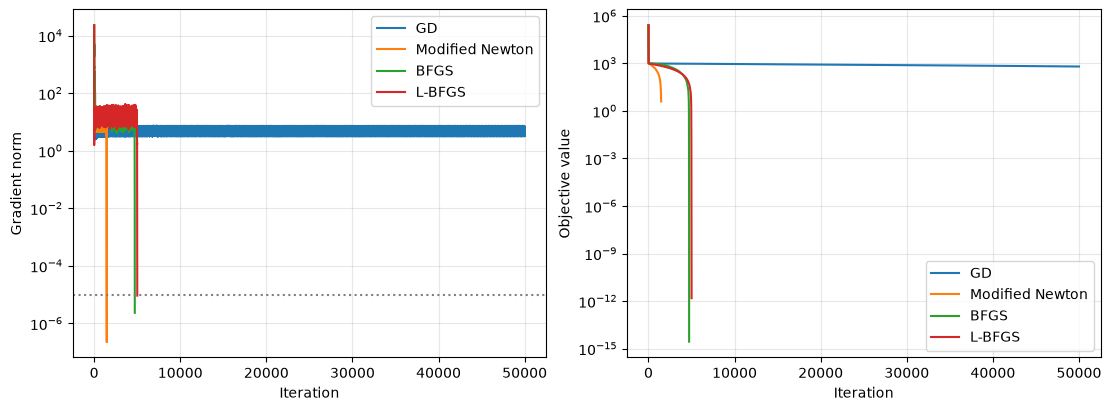

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for name in names:
    r = results[name]
    iterations = range(len(r["f"]))
    axes[0].semilogy(iterations, np.maximum(r["gnorm"], 1e-16), label=name)
    axes[1].semilogy(iterations, np.maximum(r["f"], 1e-16), label=name)
axes[0].axhline(tol, color="gray", linestyle=":")
axes[0].set_ylabel("Gradient norm")
axes[1].set_ylabel("Objective value")
for ax in axes:
    ax.set_xlabel("Iteration")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.show()
# Values below 1e-16 are displayed at 1e-16 on the logarithmic axes.

### Task 1: Convergence behavior (14 points)

Answer each question in 1–2 sentences, briefly explaining your answer using the experimental results where relevant.

1. Which methods satisfy the gradient tolerance?

   **Solution:** 
   
   Modified Newton, BFGS and L-BFGS satisfy the tolerance.

2. Which methods reach $\mathbf{x}^*=\mathbf{1}$ to numerical accuracy?

   **Solution:**

   BGFS and L-BFGS reach $\mathbf{x}^*=\mathbf{1}$ to numerical accuracy.

3. Classify any other approximate stationary point using its Hessian eigenvalues. If no such point is found, state this.

   **Solution:**
   
   Modified Newton finds a $\Vert g \Vert = 2.3 \times 10^{-7}$, and its Hessian matrix has $\lambda_{min} = 4.99 \times 10^{-1}$ and $\lambda_{max} = 1.80 \times 10^3$, which is positive definite.

   Therefore, this is a local minimum, but not a global minimum.

4. Why does a small gradient not guarantee a global minimum for this problem?

   **Solution:**

   $\Vert \nabla f \Vert = 0 $ only means the point is plant, but does not mean it is the lowest. And Rosenbrock is nonconvex and has several local minima for large $n$.

### Task 2: Computational efficiency (14 points)

Answer each question in 1–2 sentences, briefly explaining your answer using the experimental results where relevant.

1. Among the methods that reach $\mathbf{1}$ and satisfy the gradient tolerance, which has the shortest runtime?

   **Solution:**
   
   L-BFGS is the shortest.

2. Why can a method with fewer iterations take more time?

   **Solution:**
   
   In every iteration, BFGS needs to compute several $n \times n$ matrix multiplication, which takes $O(n^2)$ times, while L-BFGS only takes $O(mn)$ times. And we find $\frac n m = 100$ is corresponding to the 120 times gap.

3. Why can the objective evaluation count greatly exceed the gradient evaluation count?

   **Solution:**
   
   Gradient evaluation adds only when iterating, but objective evaluation adds when both iterating and armoji search.

4. How does the tridiagonal Hessian reduce the cost of computing a Newton step?

   **Solution:**
   
   If we use dense matrix, the matrix equation solving takes $O(n^3)$ and the storage takes $O(n^2)$. But with tridiagonal, the solving and storage all compact to $O(n)$.

### Task 3: Curvature information and memory (12 points)

Answer each question in 1–2 sentences, briefly explaining your answer using the experimental results where relevant.

1. How does each of GD, Newton, BFGS, and L-BFGS use curvature information?

   **Solution:**
   
   GD does not use any curvature information.

   Newton uses the accurate curvature information.

   BFGS and L-BFGS both use approximation, but BFGS guesses the inversion of Hessian matrix with every step of $(s, y)$, and L-BFGS guesses according to the recent $m$ steps.

2. Compare the storage orders of the four methods, excluding recorded iteration data.

   **Solution:**
   
   GD takes $O(n)$ storage.

   Newton takes $O(n)$ storage because we use banded Hessian.

   BFGS takes $O(n^2)$ storgae for it recording dense inversion of Hessian.

   L-BFGS takes $O(mn)$ storage because it re-compute $\mathbf{H}$ every time.

3. What is the purpose of the Hessian modification in Newton's method?

   **Solution:**
   
   The modification satisfies the equation has the only solution and the $\mathbf{d}$ is not that big. What's more, it also keeps $\mathbf{d}$ is towards the descent direction.

4. Why do BFGS and L-BFGS need a curvature safeguard when using Armijo backtracking?

   **Solution:**
   
   The proof of positive definiteness of BFGS is dependent on $\mathbf{s^\top y} > 0$.

## Bonus: Barzilai–Borwein methods (+25 points)

The Barzilai–Borwein (BB) method uses recent displacement and gradient differences to choose
one scalar step size. It fits either the Hessian secant equation or its inverse form with a
scalar multiple of the identity, without storing a full matrix. The iteration is

$$
\mathbf{x}_{k+1}=\mathbf{x}_k-\alpha_k\mathbf{g}_k,\qquad
\mathbf{s}_{k-1}=\mathbf{x}_k-\mathbf{x}_{k-1},\quad
\mathbf{y}_{k-1}=\mathbf{g}_k-\mathbf{g}_{k-1}.
$$

1. **Derive the two step sizes.** Assume $\mathbf{s}_{k-1}^\top\mathbf{y}_{k-1}>0$.
   Consider the scalar least-squares problems

   $$
   \beta_k=\underset{\beta\in\mathbb{R}}{\operatorname{argmin}}
   \|\beta\mathbf{s}_{k-1}-\mathbf{y}_{k-1}\|_2^2,
   \qquad \alpha_k^{\mathrm{BB1}}=\frac{1}{\beta_k},
   $$

   $$
   \alpha_k^{\mathrm{BB2}}=
   \underset{\alpha\in\mathbb{R}}{\operatorname{argmin}}
   \|\mathbf{s}_{k-1}-\alpha\mathbf{y}_{k-1}\|_2^2.
   $$

   Prove that they give

   $$
   \alpha_k^{\mathrm{BB1}}=
   \frac{\mathbf{s}_{k-1}^\top\mathbf{s}_{k-1}}
        {\mathbf{s}_{k-1}^\top\mathbf{y}_{k-1}},
   \qquad
   \alpha_k^{\mathrm{BB2}}=
   \frac{\mathbf{s}_{k-1}^\top\mathbf{y}_{k-1}}
        {\mathbf{y}_{k-1}^\top\mathbf{y}_{k-1}}.
   $$

   **(8 points)**

   **Solution:**
   
   $$
   \Vert \beta s_{k-1} - y_{k-1} \Vert _2^2= (\beta s_{k-1} - y_{k-1})^\top (\beta s_{k-1} - y_{k-1})
   $$

   $$
   \begin{aligned}
   &d((\beta s_{k-1} - y_{k-1})^\top (\beta s_{k-1} - y_{k-1})) \\
   =& d((\beta s_{k-1}^\top - y_{k-1}^\top)(\beta s_{k-1} - y_{k-1})) \\
   =& d(\beta s_{k-1}^\top - y_{k-1}^\top)(\beta s_{k-1} - y_{k-1}) + (\beta s_{k-1}^\top - y_{k-1}^\top) d(\beta s_{k-1} - y_{k-1}) \\
   =& d \beta s_{k-1}^\top (\beta s_{k-1} - y_{k-1}) + (\beta s_{k-1}^\top - y_{k-1}^\top) d \beta s_{k-1} \\
   =& \operatorname{tr}(d \beta s_{k-1}^\top (\beta s_{k-1} - y_{k-1})) + \operatorname{tr}((\beta s_{k-1}^\top - y_{k-1}^\top) d \beta s_{k-1}) \\
   =& \operatorname{tr}(s_{k-1}^\top (\beta s_{k-1} - y_{k-1}) d \beta) + \operatorname{tr}(s_{k-1} (\beta s_{k-1}^\top - y_{k-1}^\top) d \beta) \\
   =& \operatorname{tr}(2 s_{k-1}^\top (\beta s_{k-1} - y_{k-1}) d \beta) \\
   =& 2 s_{k-1}^\top (\beta s_{k-1} - y_{k-1}) d \beta
   \end{aligned}
   $$

   $$
   s_{k-1}^\top (\beta_k s_{k-1} - y_{k-1}) = 0
   $$

   $$
   \beta_k = \frac{s_{k-1}^\top y_{k-1}}{s_{k-1}^\top s_{k-1}}
   $$

   $$
   \alpha_k^{\mathrm{BB1}}=\frac{1}{\beta_k}=\frac{s_{k-1}^\top s_{k-1}}{s_{k-1}^\top y_{k-1}}
   $$

   According to the symmetry,

   $$
   \alpha_k^{\mathrm{BB2}}=\frac{s_{k-1}^\top\ y_{k-1}}{y_{k-1}^\top y_{k-1}}
   $$

2. **Interpret the curvature approximations.** Explain how BB1 fits a Hessian approximation
   $\mathbf{B}_k=\beta_k\mathbf{I}$, whereas BB2 fits an inverse-Hessian approximation
   $\mathbf{H}_k=\alpha_k^{\mathrm{BB2}}\mathbf{I}$, using their respective secant equations.
   Explain why $\mathbf{s}_{k-1}^\top\mathbf{y}_{k-1}\le0$ prevents direct use of these
   formulas as positive BB step sizes. Distinguish negative curvature from zero curvature
   and account for any zero denominators. **(6 points)**

   **Solution:**

   BB1 maximize $\Vert \beta\mathbf{s}_{k-1}-\mathbf{y}_{k-1} \Vert _2^2$, and use $B_k = \beta_k I$, so it is corresponding to Hessian matrix. And according to the symmetry, BB2 is coresponding to the inversion of Hessian matrix. 

   If $s^\top y < 0$, both formulas give a negative $\alpha$, so the step would point uphill. If $s^\top y = 0$, $\alpha^BB1 = (s^T s)/0$ is infinite, while $\alpha^BB2 = 0$ gives a zero step and no progress.

   When $y^T y = 0$ for BB2, and $s^T s = 0$ for BB1, uses $\alpha = 1$.

3. **Implement and check BB1 and BB2.** Implement **bb1** and **bb2** as separate functions.
   Use an initial trial step of 1. If $\mathbf{s}_{k-1}^\top\mathbf{y}_{k-1}\le0$, a
   denominator is zero, or the BB candidate is nonfinite, use 1 instead; clip the candidate
   to $[10^{-12},10^3]$.

   You may incorporate a line search to improve stability. If used, start it from the
   safeguarded BB candidate and briefly describe the rule. Implementing both versions
   (with and without a line search) is not required.

   Follow the stopping rules in Part 2. Without a line search, stop at the last finite point
   if a new point, objective, or gradient is nonfinite. With a line search, reject nonfinite
   trial points or objective values; stop if no step is accepted or the accepted point's
   gradient is nonfinite. Run both methods on the small test problem and report their
   iteration counts and final errors. **(6 points)**

   **Solution:** _State your line-search choice and briefly describe the rule, if used._

Without a monotone line search, objective values need not decrease at every iteration.
This bonus is independent of the Part 3 comparison.

**BB1 implementation.** Complete **bb1** below.

In [38]:
def bb1(f, grad, x0, tol=1e-5, max_iter=50000):
    """Inputs: objective f, gradient grad, initial float vector x0,
    gradient tolerance tol, and update limit max_iter.
    Return: final vector x; objective values f_values and gradient norms g_norms.
    """
    x = x0.copy()
    f_values = []
    g_norms = []

    fx = f(x)
    gx = grad(x)
    f_values.append(fx)
    g_norms.append(np.linalg.norm(gx))

    alpha = 1.0

    for _ in range(max_iter):
        if g_norms[-1] <= tol:
            break

        x_new = x - alpha * gx
        if not np.isfinite(x_new).all():
            break
        f_new = f(x_new)
        if not np.isfinite(f_new):
            break
        g_new = grad(x_new)
        if not np.isfinite(g_new).all():
            break

        s = x_new - x
        y = g_new - gx
        sty = np.dot(s, y)

        if sty > 0:
            cand = (np.dot(s, s)) / sty
            alpha = min(max(cand, 1e-12), 1e3) if np.isfinite(cand) else 1.0
        else:
            alpha = 1.0

        x, fx, gx = x_new, f_new, g_new
        f_values.append(fx)
        g_norms.append(np.linalg.norm(gx))
    return x, f_values, g_norms

**Quick Check: BB1.** After completing **bb1**, uncomment and run the following cell.

In [39]:
x_bb1, f_bb1, g_bb1 = bb1(
    test_objective, test_gradient, z0, check_tol, check_max_iter)
print("Iterations:", len(f_bb1) - 1)
print("Final error:", np.linalg.norm(x_bb1 - z_star))

Iterations: 34
Final error: 6.102154426583742e-14


**BB2 implementation.** Complete **bb2** below.

In [40]:
def bb2(f, grad, x0, tol=1e-5, max_iter=50000):
    """Inputs: objective f, gradient grad, initial float vector x0,
    gradient tolerance tol, and update limit max_iter.
    Return: final vector x; objective values f_values and gradient norms g_norms.
    """
    x = x0.copy()
    f_values = []
    g_norms = []

    fx = f(x)
    gx = grad(x)
    f_values.append(fx)
    g_norms.append(np.linalg.norm(gx))

    alpha = 1.0

    for _ in range(max_iter):
        if g_norms[-1] <= tol:
            break

        x_new = x - alpha * gx
        if not np.isfinite(x_new).all():
            break
        f_new = f(x_new)
        if not np.isfinite(f_new):
            break
        g_new = grad(x_new)
        if not np.isfinite(g_new).all():
            break

        s = x_new - x
        y = g_new - gx
        sty = np.dot(s, y)

        if sty > 0:
            cand = sty / (np.dot(y, y))
            alpha = min(max(cand, 1e-12), 1e3) if np.isfinite(cand) else 1.0
        else:
            alpha = 1.0

        x, fx, gx = x_new, f_new, g_new
        f_values.append(fx)
        g_norms.append(np.linalg.norm(gx))
    return x, f_values, g_norms

**Quick Check: BB2.** After completing **bb2**, uncomment and run the following cell.

In [41]:
x_bb2, f_bb2, g_bb2 = bb2(
    test_objective, test_gradient, z0, check_tol, check_max_iter)
print("Iterations:", len(f_bb2) - 1)
print("Final error:", np.linalg.norm(x_bb2 - z_star))

Iterations: 37
Final error: 4.951979951983718e-13


4. **Comparison with gradient descent.** Run BB1 and BB2 on the $n=1000$ Rosenbrock
   problem using the same initial point, gradient tolerance, and iteration limit as in
   Part 3. Reuse the GD results.

   Report the iteration counts, final objective values, gradient norms, distances to
   $\mathbf{1}$, objective/gradient evaluation counts, and runtimes. Plot the objective
   values and gradient norms against iteration for all three methods.

   Compare their efficiency and stability, relating your observations to the BB step sizes
   and the use of Armijo backtracking in GD. Include unsuccessful runs and explain any
   objective increases or numerical failures. State whether a line search is used for each
   BB method and discuss its effect on stability and computational cost. **(5 points)**

For a failed run, report and plot the last finite iterates retained by the algorithm.
Evaluation counts include attempted evaluations before termination.

After completing BB1 and BB2, uncomment and run the following three cells.

In [45]:
# Reuse GD from Part 3; run only BB1 and BB2 here.
bb_results = {"GD": results["GD"]}
bb_names = ["GD", "BB1", "BB2"]

for name in ["BB1", "BB2"]:
    counts = [0, 0, 0]
    x0 = initial_point(n)
    start = perf_counter()
    if name == "BB1":
        x, f_values, g_norms = bb1(
            counted_objective, counted_gradient, x0, tol, max_iter)
    else:
        x, f_values, g_norms = bb2(
            counted_objective, counted_gradient, x0, tol, max_iter)
    runtime = perf_counter() - start
    bb_results[name] = {
        "x": x, "f": f_values, "gnorm": g_norms,
        "runtime": runtime, "nf": counts[0], "ng": counts[1],
        "distance": np.linalg.norm(x - np.ones(n))
    }

C:\Users\Xenon\AppData\Local\Temp\ipykernel_12512\3659749209.py:16: RuntimeWarning: overflow encountered in square
  return np.sum(100 * (x[1:] - x[:-1]**2)**2 + (1 - x[:-1])**2)


In [43]:
print("GD and BB: final points")
print(f"{'Method':<8} {'Iter':>7} {'f':>13} {'|g|':>13} {'|x-1|':>13}")
for name in bb_names:
    r = bb_results[name]
    print(f"{name:<8} {len(r['f'])-1:7d} {r['f'][-1]:13.3e} "
          f"{r['gnorm'][-1]:13.3e} {r['distance']:13.3e}")

print("\nGD and BB: computational cost")
print(f"{'Method':<8} {'f calls':>10} {'g calls':>10} {'Time (s)':>12}")
for name in bb_names:
    r = bb_results[name]
    print(f"{name:<8} {r['nf']:10d} {r['ng']:10d} {r['runtime']:12.3f}")

GD and BB: final points
Method      Iter             f           |g|         |x-1|
GD         50000     6.351e+02     3.443e+00     2.509e+01
BB1           30    4.098e+121     2.049e+92     8.001e+29
BB2        22102     1.292e-11     5.518e-06     7.190e-06

GD and BB: computational cost
Method      f calls    g calls     Time (s)
GD           538043      50001        5.895
BB1              32         31        0.002
BB2           22103      22103        0.539


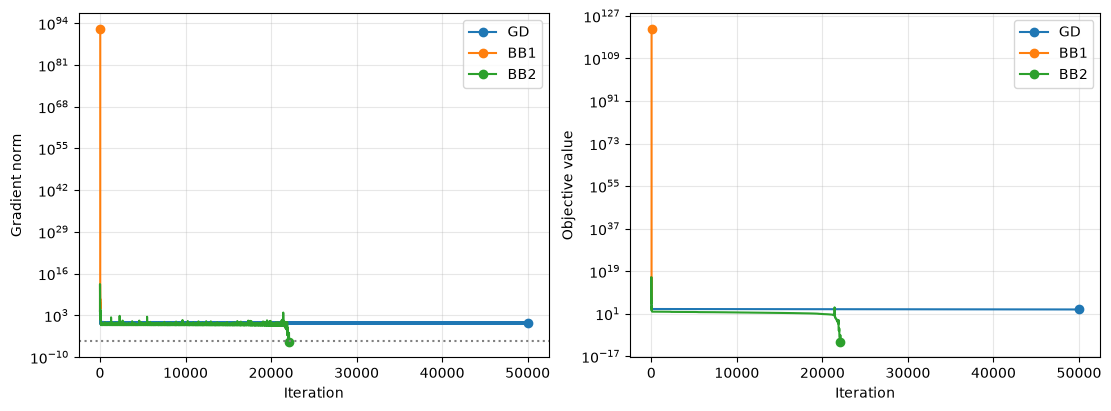

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for name in bb_names:
    r = bb_results[name]
    iterations = range(len(r["f"]))
    axes[0].semilogy(iterations, np.maximum(r["gnorm"], 1e-16),
                     label=name, marker="o", markevery=[len(r["f"])-1])
    axes[1].semilogy(iterations, np.maximum(r["f"], 1e-16),
                     label=name, marker="o", markevery=[len(r["f"])-1])
axes[0].axhline(tol, color="gray", linestyle=":")
axes[0].set_ylabel("Gradient norm")
axes[1].set_ylabel("Objective value")
for ax in axes:
    ax.set_xlabel("Iteration")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.show()
# A marker indicates each run's last retained iterate.

**Solution:** _Your comparison and explanation._

**Before submission:** restart the kernel, run all required code cells in order,
and save the notebook with its outputs. If you complete the bonus, also run its checks
and experiments. The notebook must run without additional data files.

Report any changes to the prescribed algorithms or experiment settings; otherwise write "None."

**Changes:**

None.